In [1]:
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/raw/energydata_complete.csv")

In [4]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [5]:
df.shape

(19735, 29)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [7]:
df.isnull().sum()

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["date"]=pd.to_datetime(df["date"])

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[ns]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7

In [11]:
df=df.sort_values("date")

In [12]:
df=df.reset_index(drop=True)

In [13]:
df["date"].diff().value_counts().head()

date
0 days 00:10:00    19734
Name: count, dtype: int64

In [14]:
df["Appliances"].describe()

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

In [15]:
df["Appliances"].unique()

array([  60,   50,   70,  230,  580,  430,  250,  100,   90,   80,  140,
        120,  190,  110,  400,  390,  240,   40,   30,  310,  380,  370,
         20,  260,  500,  450,  220,  170,  290,  130,  200,  210,  180,
        350,  300,  340,  150,  330,  420,  520,  360,  270,  550,  690,
        620,  610,  490,  410,  320,  740,  910,  510,  790,  460,  160,
        480,  280,  560, 1080,  750,  470,  440,  800,  540,  530,  660,
        630,  600,   10,  570,  830, 1070,  890,  590,  850,  710,  680,
        670,  780,  640,  650,  700,  770,  720,  760,  860,  880,  730,
        900,  820,  870,  840])

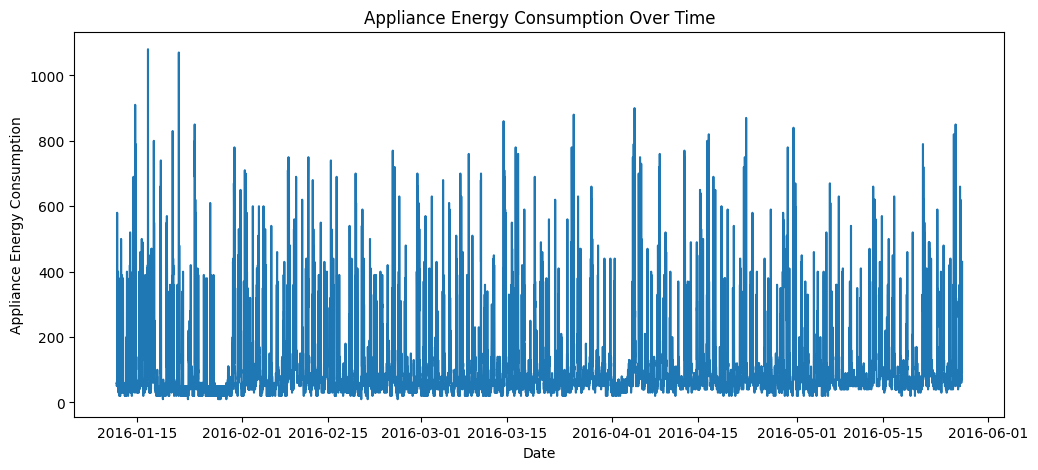

In [16]:
plt.figure(figsize=(12,5))

plt.plot(df["date"], df["Appliances"])

plt.xlabel("Date")
plt.ylabel("Appliance Energy Consumption")
plt.title("Appliance Energy Consumption Over Time")

plt.show()

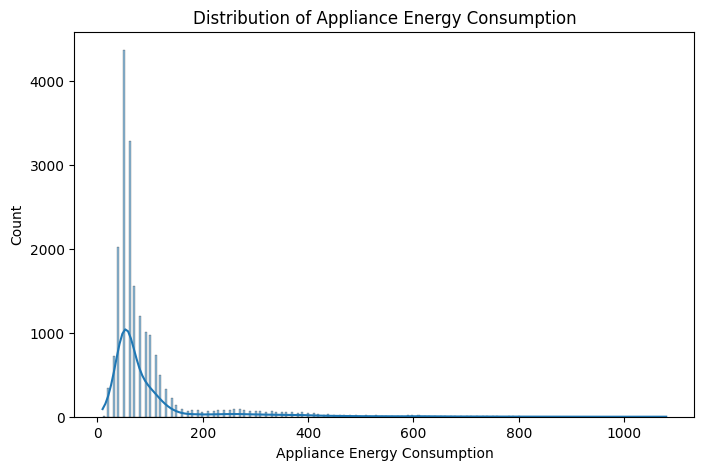

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df["Appliances"], kde=True)

plt.xlabel("Appliance Energy Consumption")
plt.title("Distribution of Appliance Energy Consumption")

plt.show()

In [18]:
corr=df.corr(numeric_only=True)

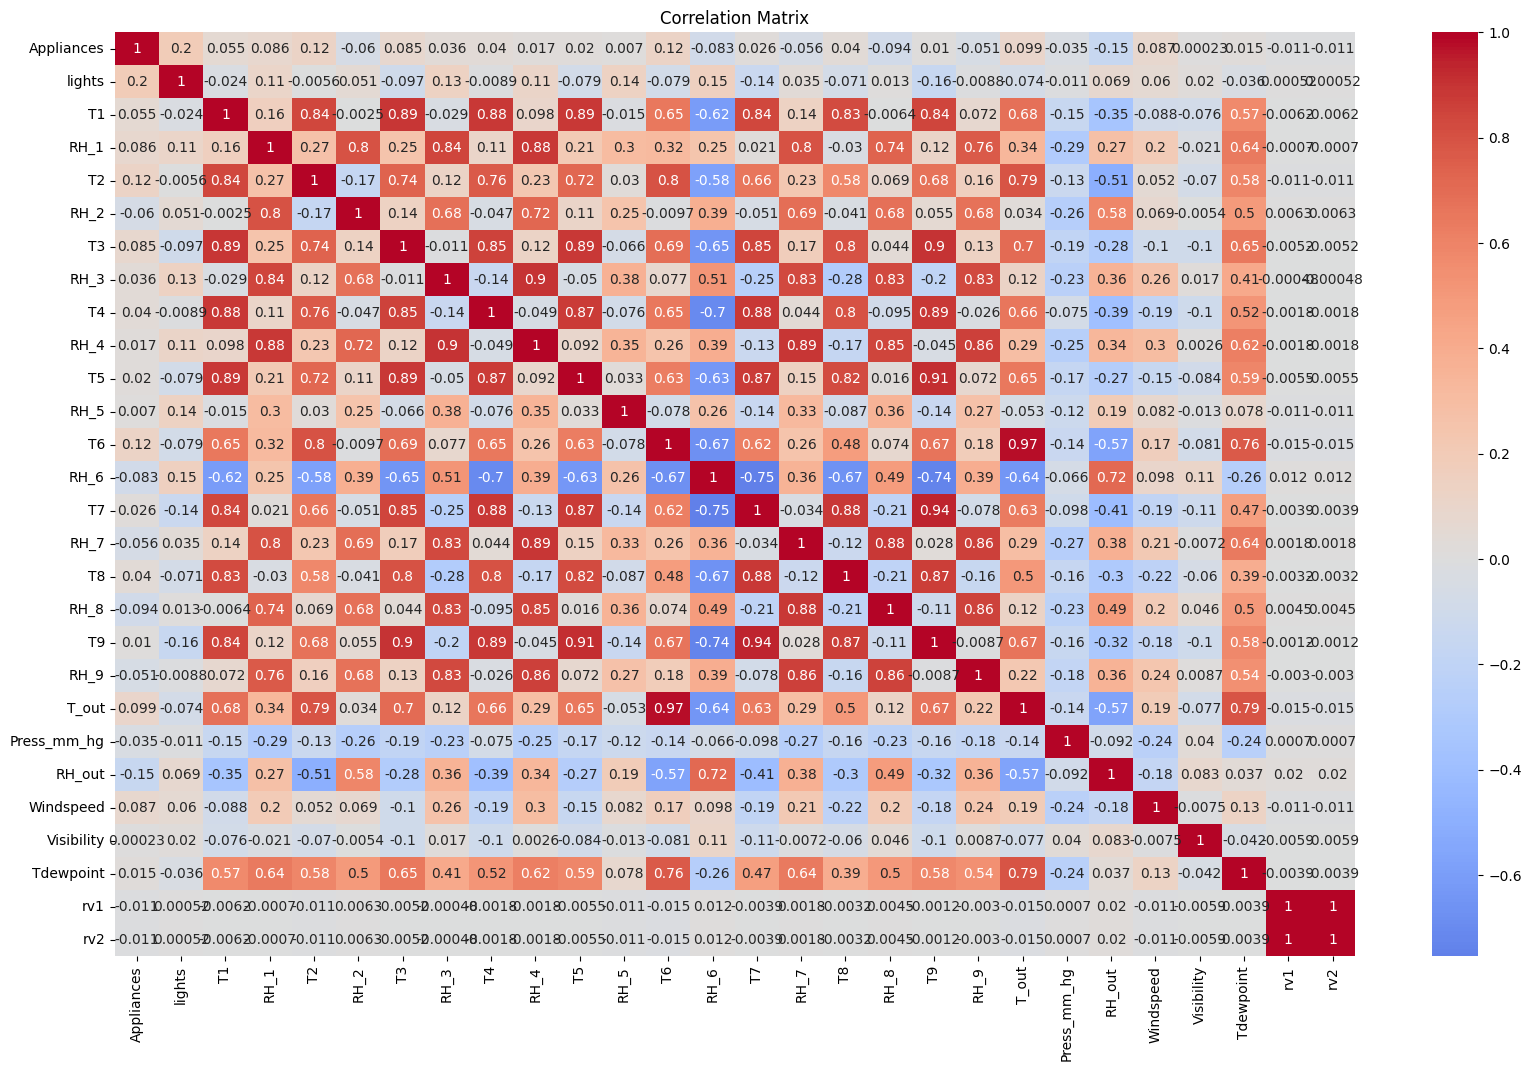

In [19]:
plt.figure(figsize=(20,12))
sns.heatmap(corr,cmap="coolwarm",center=0,annot=True)
plt.title("Correlation Matrix")
plt.show()

correlation with our target

In [20]:
target_corr = corr["Appliances"].sort_values(ascending=False)

In [21]:
print(target_corr)

Appliances     1.000000
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099155
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
T9             0.010010
RH_5           0.006955
Visibility     0.000230
rv1           -0.011145
rv2           -0.011145
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64


In [22]:
df["hour"] = df["date"].dt.hour
df["day"] = df["date"].dt.day
df["minute"]=df["date"].dt.minute
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

In [23]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Visibility,Tdewpoint,rv1,rv2,hour,day,minute,month,day_of_week,is_weekend
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,63.000000,5.3,13.275433,13.275433,17,11,0,1,0,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,59.166667,5.2,18.606195,18.606195,17,11,10,1,0,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,55.333333,5.1,28.642668,28.642668,17,11,20,1,0,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,51.500000,5.0,45.410389,45.410389,17,11,30,1,0,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,47.666667,4.9,10.084097,10.084097,17,11,40,1,0,0


lag_1  = 10 minutes ago

lag_2  = 20 minutes ago

lag_3  = 30 minutes ago

lag_6  = 1 hour ago

lag_12 = 2 hours ago

lag_24 = 4 hours ago

In [24]:
df["Appliances_lag_1"] = df["Appliances"].shift(1)
df["Appliances_lag_2"] = df["Appliances"].shift(2)
df["Appliances_lag_3"] = df["Appliances"].shift(3)
df["Appliances_lag_6"] = df["Appliances"].shift(6)
df["Appliances_lag_12"] = df["Appliances"].shift(12)
df["Appliances_lag_24"] = df["Appliances"].shift(24)
df["Appliances_lag_36"] = df["Appliances"].shift(36)
df["Appliances_lag_48"] = df["Appliances"].shift(48)

# Same time yesterday
df["Appliances_lag_144"] = df["Appliances"].shift(144)

# Same time one week ago
df["Appliances_lag_1008"] = df["Appliances"].shift(1008)

In [25]:
df.head(10)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Appliances_lag_1,Appliances_lag_2,Appliances_lag_3,Appliances_lag_6,Appliances_lag_12,Appliances_lag_24,Appliances_lag_36,Appliances_lag_48,Appliances_lag_144,Appliances_lag_1008
0,2016-01-11 17:00:00,60,30,19.890000,47.596667,19.20,44.790000,19.79,44.730000,19.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-01-11 17:10:00,60,30,19.890000,46.693333,19.20,44.722500,19.79,44.790000,19.000000,...,60.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-01-11 17:20:00,50,30,19.890000,46.300000,19.20,44.626667,19.79,44.933333,18.926667,...,60.0,60.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-01-11 17:30:00,50,40,19.890000,46.066667,19.20,44.590000,19.79,45.000000,18.890000,...,50.0,60.0,60.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-01-11 17:40:00,60,40,19.890000,46.333333,19.20,44.530000,19.79,45.000000,18.890000,...,50.0,50.0,60.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2016-01-11 17:50:00,50,40,19.890000,46.026667,19.20,44.500000,19.79,44.933333,18.890000,...,60.0,50.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2016-01-11 18:00:00,60,50,19.890000,45.766667,19.20,44.500000,19.79,44.900000,18.890000,...,50.0,60.0,50.0,60.0,NaN,NaN,NaN,NaN,NaN,NaN
7,2016-01-11 18:10:00,60,50,19.856667,45.560000,19.20,44.500000,19.73,44.900000,18.890000,...,60.0,50.0,60.0,60.0,NaN,NaN,NaN,NaN,NaN,NaN
8,2016-01-11 18:20:00,60,40,19.790000,45.597500,19.20,44.433333,19.73,44.790000,18.890000,...,60.0,60.0,50.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN
9,2016-01-11 18:30:00,70,40,19.856667,46.090000,19.23,44.400000,19.79,44.863333,18.890000,...,60.0,60.0,60.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
df.tail()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Appliances_lag_1,Appliances_lag_2,Appliances_lag_3,Appliances_lag_6,Appliances_lag_12,Appliances_lag_24,Appliances_lag_36,Appliances_lag_48,Appliances_lag_144,Appliances_lag_1008
19730,2016-05-27 17:20:00,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.7,...,90.0,110.0,120.0,100.0,80.0,240.0,400.0,70.0,600.0,80.0
19731,2016-05-27 17:30:00,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.7,...,100.0,90.0,110.0,220.0,80.0,250.0,620.0,50.0,520.0,70.0
19732,2016-05-27 17:40:00,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.7,...,90.0,100.0,90.0,180.0,70.0,220.0,330.0,580.0,290.0,80.0
19733,2016-05-27 17:50:00,420,10,25.500000,46.990000,25.414000,43.036000,26.890000,41.290000,24.7,...,270.0,90.0,100.0,120.0,100.0,230.0,250.0,660.0,250.0,70.0
19734,2016-05-27 18:00:00,430,10,25.500000,46.600000,25.264286,42.971429,26.823333,41.156667,24.7,...,420.0,270.0,90.0,110.0,100.0,190.0,260.0,300.0,190.0,90.0


In [27]:
df["rolling_mean_6"] = (
    df["Appliances"]
    .shift(1)
    .rolling(window=6)
    .mean()
)

In [28]:
df["rolling_mean_12"] = (
    df["Appliances"]
    .shift(1)
    .rolling(window=12)
    .mean()
)

In [29]:
df["rolling_std_6"] = (
    df["Appliances"]
    .shift(1)
    .rolling(window=12)
    .std()
)

In [30]:
df["rolling_mean_24"] = (
    df["Appliances"]
    .shift(1)
    .rolling(24)
    .mean()
)

df["rolling_std_24"] = (
    df["Appliances"]
    .shift(1)
    .rolling(24)
    .std()
)

In [31]:
df["rolling_mean_144"] = (
    df["Appliances"]
    .shift(1)
    .rolling(144)
    .mean()
)

In [32]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Appliances_lag_36,Appliances_lag_48,Appliances_lag_144,Appliances_lag_1008,rolling_mean_6,rolling_mean_12,rolling_std_6,rolling_mean_24,rolling_std_24,rolling_mean_144
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
df.isnull().sum()

date                      0
Appliances                0
lights                    0
T1                        0
RH_1                      0
T2                        0
RH_2                      0
T3                        0
RH_3                      0
T4                        0
RH_4                      0
T5                        0
RH_5                      0
T6                        0
RH_6                      0
T7                        0
RH_7                      0
T8                        0
RH_8                      0
T9                        0
RH_9                      0
T_out                     0
Press_mm_hg               0
RH_out                    0
Windspeed                 0
Visibility                0
Tdewpoint                 0
rv1                       0
rv2                       0
hour                      0
day                       0
minute                    0
month                     0
day_of_week               0
is_weekend                0
Appliances_lag_1    

In [34]:
df = df.dropna().reset_index(drop=True)

In [35]:
df.isnull().sum()

date                   0
Appliances             0
lights                 0
T1                     0
RH_1                   0
T2                     0
RH_2                   0
T3                     0
RH_3                   0
T4                     0
RH_4                   0
T5                     0
RH_5                   0
T6                     0
RH_6                   0
T7                     0
RH_7                   0
T8                     0
RH_8                   0
T9                     0
RH_9                   0
T_out                  0
Press_mm_hg            0
RH_out                 0
Windspeed              0
Visibility             0
Tdewpoint              0
rv1                    0
rv2                    0
hour                   0
day                    0
minute                 0
month                  0
day_of_week            0
is_weekend             0
Appliances_lag_1       0
Appliances_lag_2       0
Appliances_lag_3       0
Appliances_lag_6       0
Appliances_lag_12      0


In [36]:
X = df.drop(columns=["Appliances", "date"])
y = df["Appliances"]

In [37]:
print(X.shape)
print(y.shape)

(18727, 49)
(18727,)


In [38]:
print(X.columns)

Index(['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5',
       'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out',
       'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1',
       'rv2', 'hour', 'day', 'minute', 'month', 'day_of_week', 'is_weekend',
       'Appliances_lag_1', 'Appliances_lag_2', 'Appliances_lag_3',
       'Appliances_lag_6', 'Appliances_lag_12', 'Appliances_lag_24',
       'Appliances_lag_36', 'Appliances_lag_48', 'Appliances_lag_144',
       'Appliances_lag_1008', 'rolling_mean_6', 'rolling_mean_12',
       'rolling_std_6', 'rolling_mean_24', 'rolling_std_24',
       'rolling_mean_144'],
      dtype='object')


In [39]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [40]:
X_train.shape

(14981, 49)

In [41]:
X_test.shape

(3746, 49)

In [42]:
print("Training period:")
print(df["date"].iloc[0])
print(df["date"].iloc[split_index - 1])

print("\nTesting period:")
print(df["date"].iloc[split_index])
print(df["date"].iloc[-1])

Training period:
2016-01-18 17:00:00
2016-05-01 17:40:00

Testing period:
2016-05-01 17:50:00
2016-05-27 18:00:00


In [43]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [44]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [45]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae_lr = mean_absolute_error(y_test, y_pred_lr)

mse_lr = mean_squared_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mse_lr)

r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("MAE :", mae_lr)
print("MSE :", mse_lr)
print("RMSE:", rmse_lr)
print("R2  :", r2_lr)

Linear Regression
MAE : 27.135094993095606
MSE : 3381.342734218336
RMSE: 58.14931413368808
R2  : 0.5560210057056529


In [46]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [47]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R2  :", r2_rf)

Random Forest
MAE : 68.47285104111052
MSE : 9907.389612920448
RMSE: 99.53587098589357
R2  : -0.3008657276629252


In [48]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

In [49]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)

mse_gb = mean_squared_error(y_test, y_pred_gb)

rmse_gb = np.sqrt(mse_gb)

r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting")
print("MAE :", mae_gb)
print("MSE :", mse_gb)
print("RMSE:", rmse_gb)
print("R2  :", r2_gb)

Gradient Boosting
MAE : 112.10385883599446
MSE : 20531.03530772
RMSE: 143.28654963994353
R2  : -1.695777720341162


In [50]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [51]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective="reg:squarederror"
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

In [52]:
mae_xgb = mean_absolute_error(y_test,y_pred_xgb)

mse_xgb = mean_squared_error(y_test,y_pred_xgb)

rmse_xgb = np.sqrt(mse_xgb)

r2_xgb = r2_score(y_test,y_pred_xgb)

print("XGBoost")
print("MAE :", mae_xgb)
print("MSE :", mse_xgb)
print("RMSE:", rmse_xgb)
print("R2  :", r2_xgb)

XGBoost
MAE : 71.183837890625
MSE : 9366.423828125
RMSE: 96.7802863610405
R2  : -0.2298356294631958


In [53]:
results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],

    "MAE": [
        mae_lr,
        mae_rf,
        mae_gb,
        mae_xgb
    ],

    "MSE": [
        mse_lr,
        mse_rf,
        mse_gb,
        mse_xgb
    ],

    "RMSE": [
        rmse_lr,
        rmse_rf,
        rmse_gb,
        rmse_xgb
    ],

    "R2": [
        r2_lr,
        r2_rf,
        r2_gb,
        r2_xgb
    ]
})

results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,27.135095,3381.342734,58.149314,0.556021
1,Random Forest,68.472851,9907.389613,99.535871,-0.300866
2,Gradient Boosting,112.103859,20531.035308,143.286550,-1.695778
3,XGBoost,71.183838,9366.423828,96.780286,-0.229836


In [54]:
print(X_train.shape)
print(X_test.shape)

print(X_train.columns.tolist())

(14981, 49)
(3746, 49)
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'day', 'minute', 'month', 'day_of_week', 'is_weekend', 'Appliances_lag_1', 'Appliances_lag_2', 'Appliances_lag_3', 'Appliances_lag_6', 'Appliances_lag_12', 'Appliances_lag_24', 'Appliances_lag_36', 'Appliances_lag_48', 'Appliances_lag_144', 'Appliances_lag_1008', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_6', 'rolling_mean_24', 'rolling_std_24', 'rolling_mean_144']


In [55]:
print(
    df[
        [
            "Appliances",
            "Appliances_lag_1",
            "Appliances_lag_6",
            "Appliances_lag_24",
            "rolling_mean_6"
        ]
    ].head(30)
)

    Appliances  Appliances_lag_1  Appliances_lag_6  Appliances_lag_24  \
0           40              50.0              50.0               20.0   
1           40              40.0              50.0               30.0   
2           40              40.0              50.0               40.0   
3           40              40.0              40.0               50.0   
4           20              40.0              40.0               50.0   
5           30              20.0              50.0               50.0   
6           30              30.0              40.0               40.0   
7           70              30.0              40.0               40.0   
8          230              70.0              40.0               40.0   
9          660             230.0              40.0               40.0   
10         510             660.0              20.0               40.0   
11         300             510.0              30.0               50.0   
12         300             300.0              30.0 

In [56]:
print("TRAIN TARGET")
print(y_train.describe())

print("\nTEST TARGET")
print(y_test.describe())

TRAIN TARGET
count    14981.000000
mean        97.438088
std        103.770272
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1070.000000
Name: Appliances, dtype: float64

TEST TARGET
count    3746.000000
mean       94.361986
std        87.281331
min        20.000000
25%        50.000000
50%        60.000000
75%       100.000000
max       850.000000
Name: Appliances, dtype: float64


In [57]:
print("NaN in y_train:", y_train.isna().sum())
print("NaN in y_test :", y_test.isna().sum())

NaN in y_train: 0
NaN in y_test : 0


In [58]:
print("X_train NaN:", X_train.isna().sum().sum())
print("X_test NaN :", X_test.isna().sum().sum())

X_train NaN: 0
X_test NaN : 0


In [59]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (14981, 49)
y_train shape: (14981,)
X_test shape: (3746, 49)
y_test shape: (3746,)


In [60]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

baseline_pred = X_test["Appliances_lag_1"]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_mse = mean_squared_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(baseline_mse)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

print("Naive Baseline")
print("MAE :", baseline_mae)
print("MSE :", baseline_mse)
print("RMSE:", baseline_rmse)
print("R2  :", baseline_r2)

Naive Baseline
MAE : 25.678056593699946
MSE : 4180.165509877203
RMSE: 64.65419947595981
R2  : 0.45113352152152475


In [61]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(20))

             Feature  Importance
33  Appliances_lag_1    0.348872
34  Appliances_lag_2    0.033447
28               day    0.028595
30             month    0.026657
47    rolling_std_24    0.023419
27              hour    0.023404
46   rolling_mean_24    0.021923
31       day_of_week    0.019457
19             T_out    0.018233
43    rolling_mean_6    0.018001
23        Visibility    0.016852
12              RH_6    0.016756
7                 T4    0.016448
17                T9    0.016431
35  Appliances_lag_3    0.014932
44   rolling_mean_12    0.014852
22         Windspeed    0.014217
48  rolling_mean_144    0.014150
21            RH_out    0.014006
45     rolling_std_6    0.013727


In [62]:
print(
    X_train[
        [
            "Appliances_lag_1",
            "Appliances_lag_2",
            "Appliances_lag_6",
            "Appliances_lag_24",
            "rolling_mean_6",
            "rolling_mean_12"
        ]
    ].corr()
)

                   Appliances_lag_1  Appliances_lag_2  Appliances_lag_6  \
Appliances_lag_1           1.000000          0.755576          0.366581   
Appliances_lag_2           0.755576          1.000000          0.399134   
Appliances_lag_6           0.366581          0.399134          1.000000   
Appliances_lag_24          0.132524          0.137794          0.181743   
rolling_mean_6             0.732887          0.814203          0.732646   
rolling_mean_12            0.642048          0.691658          0.744879   

                   Appliances_lag_24  rolling_mean_6  rolling_mean_12  
Appliances_lag_1            0.132524        0.732887         0.642048  
Appliances_lag_2            0.137794        0.814203         0.691658  
Appliances_lag_6            0.181743        0.732646         0.744879  
Appliances_lag_24           1.000000        0.195923         0.294359  
rolling_mean_6              0.195923        1.000000         0.889858  
rolling_mean_12             0.294359      

In [63]:
time_features = [
    "hour",
    "minute",
    "day",
    "month",
    "day_of_week",
    "is_weekend",

    "Appliances_lag_1",
    "Appliances_lag_2",
    "Appliances_lag_3",
    "Appliances_lag_6",
    "Appliances_lag_12",
    "Appliances_lag_24",

    "rolling_mean_6",
    "rolling_mean_12",
    "rolling_std_6"
]

In [64]:
X_time = df[time_features]
y_time = df["Appliances"]

In [65]:
split_index = int(len(df) * 0.8)

X_train_time = X_time.iloc[:split_index]
X_test_time = X_time.iloc[split_index:]

y_train_time = y_time.iloc[:split_index]
y_test_time = y_time.iloc[split_index:]

In [66]:
from xgboost import XGBRegressor

xgb_time = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective="reg:squarederror"
)

xgb_time.fit(
    X_train_time,
    y_train_time
)

y_pred_time = xgb_time.predict(
    X_test_time
)

In [67]:
mae = mean_absolute_error(
    y_test_time,
    y_pred_time
)

mse = mean_squared_error(
    y_test_time,
    y_pred_time
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_time,
    y_pred_time
)

print("XGBoost - Time Features Only")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

XGBoost - Time Features Only
MAE : 26.14702796936035
MSE : 3394.37109375
RMSE: 58.261231481577866
R2  : 0.5543103218078613


In [68]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "objective":["reg:squarederror","reg:pseudohubererror"],
}

In [69]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

In [70]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    random_state=42
)

In [71]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

In [72]:
grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 200, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know mo

In [73]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300, 'objective': 'reg:squarederror', 'subsample': 0.8}


In [74]:
print(
    "Best CV RMSE:",
    -grid_search.best_score_
)

Best CV RMSE: 64.76574478149413


In [75]:
best_xgb = grid_search.best_estimator_

y_pred_tuned = best_xgb.predict(X_test)

In [76]:
mae_tuned = mean_absolute_error(
    y_test,
    y_pred_tuned
)

mse_tuned = mean_squared_error(
    y_test,
    y_pred_tuned
)

rmse_tuned = np.sqrt(mse_tuned)

r2_tuned = r2_score(
    y_test,
    y_pred_tuned
)

print("Tuned XGBoost")
print("MAE :", mae_tuned)
print("MSE :", mse_tuned)
print("RMSE:", rmse_tuned)
print("R2  :", r2_tuned)

Tuned XGBoost
MAE : 30.24468994140625
MSE : 3482.991943359375
RMSE: 59.0168784616687
R2  : 0.54267418384552


In [77]:
print("Best XGBoost Parameters:")
print(grid_search.best_params_)

Best XGBoost Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300, 'objective': 'reg:squarederror', 'subsample': 0.8}


In [78]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [79]:
rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple m

In [80]:
print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print(
    "Best CV RMSE",
    -rf_grid.best_score_
)

Best Random Forest Parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV RMSE 67.52223097697042


In [81]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

mae_rf_tuned = mean_absolute_error(
    y_test,
    y_pred_rf_tuned
)

mse_rf_tuned = mean_squared_error(
    y_test,
    y_pred_rf_tuned
)

rmse_rf_tuned = np.sqrt(mse_rf_tuned)

r2_rf_tuned = r2_score(
    y_test,
    y_pred_rf_tuned
)

print("\nTuned Random Forest")
print("MAE :", mae_rf_tuned)
print("MSE :", mse_rf_tuned)
print("RMSE:", rmse_rf_tuned)
print("R2  :", r2_rf_tuned)


Tuned Random Forest
MAE : 44.884382628082534
MSE : 5680.537583508807
RMSE: 75.3693411375528
R2  : 0.25413081085952094


In [82]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

gb_model = GradientBoostingRegressor(
    random_state=42
)

In [83]:
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [84]:
gb_grid = GridSearchCV(
    estimator=gb_model,
    param_grid=gb_param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

gb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multipl

In [85]:
print("Best Gradient Boosting Parameters:")
print(gb_grid.best_params_)

print(
    "Best CV RMSE:",
    -gb_grid.best_score_
)

Best Gradient Boosting Parameters:
{'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV RMSE: 66.43977483350292


In [86]:
best_gb = gb_grid.best_estimator_

y_pred_gb_tuned = best_gb.predict(X_test)

mae_gb_tuned = mean_absolute_error(
    y_test,
    y_pred_gb_tuned
)

mse_gb_tuned = mean_squared_error(
    y_test,
    y_pred_gb_tuned
)

rmse_gb_tuned = np.sqrt(mse_gb_tuned)

r2_gb_tuned = r2_score(
    y_test,
    y_pred_gb_tuned
)

print("\nTuned Gradient Boosting")
print("MAE :", mae_gb_tuned)
print("MSE :", mse_gb_tuned)
print("RMSE:", rmse_gb_tuned)
print("R2  :", r2_gb_tuned)


Tuned Gradient Boosting
MAE : 24.96459576122403
MSE : 3301.7312165900353
RMSE: 57.460692795945604
R2  : 0.5664742026481482


In [87]:
final_results = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest",
        "Gradient Boosting",
        "Tuned Gradient Boosting",
        "XGBoost",
        "Tuned XGBoost"
    ],

    "MAE": [
        baseline_mae,
        mae_lr,
        mae_rf,
        mae_rf_tuned,
        mae_gb,
        mae_gb_tuned,
        mae_xgb,
        mae_tuned
    ],

    "RMSE": [
        baseline_rmse,
        rmse_lr,
        rmse_rf,
        rmse_rf_tuned,
        rmse_gb,
        rmse_gb_tuned,
        rmse_xgb,
        rmse_tuned
    ],

    "R2": [
        baseline_r2,
        r2_lr,
        r2_rf,
        r2_rf_tuned,
        r2_gb,
        r2_gb_tuned,
        r2_xgb,
        r2_tuned
    ]
})

final_results

,Model,MAE,RMSE,R2
0,Naive Baseline,25.678057,64.654199,0.451134
1,Linear Regression,27.135095,58.149314,0.556021
2,Random Forest,68.472851,99.535871,-0.300866
3,Tuned Random Forest,44.884383,75.369341,0.254131
4,Gradient Boosting,112.103859,143.286550,-1.695778
5,Tuned Gradient Boosting,24.964596,57.460693,0.566474
6,XGBoost,71.183838,96.780286,-0.229836
7,Tuned XGBoost,30.244690,59.016878,0.542674


In [88]:
best_model = final_results.loc[
    final_results["RMSE"].idxmin()
]

print("Best model based on RMSE:")
print(best_model)

Best model based on RMSE:
Model    Tuned Gradient Boosting
MAE                    24.964596
RMSE                   57.460693
R2                      0.566474
Name: 5, dtype: object


In [89]:
best_r2 = final_results.loc[
    final_results["R2"].idxmax()
]

print("\nBest model based on R2:")
print(best_r2)


Best model based on R2:
Model    Tuned Gradient Boosting
MAE                    24.964596
RMSE                   57.460693
R2                      0.566474
Name: 5, dtype: object


In [90]:
print(X_train.columns.tolist())

['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'day', 'minute', 'month', 'day_of_week', 'is_weekend', 'Appliances_lag_1', 'Appliances_lag_2', 'Appliances_lag_3', 'Appliances_lag_6', 'Appliances_lag_12', 'Appliances_lag_24', 'Appliances_lag_36', 'Appliances_lag_48', 'Appliances_lag_144', 'Appliances_lag_1008', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_6', 'rolling_mean_24', 'rolling_std_24', 'rolling_mean_144']


In [91]:
print("Number of features:", len(X_train.columns))

Number of features: 49


In [92]:
print("Best Gradient Boosting Parameters:")
print(gb_grid.best_params_)

Best Gradient Boosting Parameters:
{'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
